# 1. What the flight boards give us

AeroScrape scrapes the public flight information pages of Iran Airports Company (fids.airport.ir), one page per airport. This notebook looks at the 2025 archive the models are trained on: how much survives cleaning, which airports and flight types it covers, and the gap that limits the model most, missing aircraft registrations.

Data: `make data` downloads the archive. Cleaning is the pipeline's own (`aeroscrape.data.clean`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import nbutils
from nbutils import BLUE, GREEN, GREY, ORANGE, RED

nbutils.setup()

In [2]:
flights, audit = nbutils.load_flights()
print(f"{len(flights):,} flights, {flights['scheduled_datetime'].min():%Y-%m-%d} to {flights['scheduled_datetime'].max():%Y-%m-%d}")
display(Markdown(audit.to_markdown()))

Ignoring 3 implausible delays outside [-60, 720] min


15,732 flights, 2025-05-22 to 2025-06-13


| Step | Rows |
| --- | --- |
| Raw scraped rows | 15,732 |
| With a scheduled time and flight number | 15,732 |
| After removing duplicate flights | 15,732 |

## From raw rows to training rows

The archive holds one row per flight: it was exported from the database, where every scrape of a flight updates the same row (the scraper sees a flight several times as its status changes). Training uses only domestic departures that actually departed with a plausible delay, and the cleaner counts every row it drops:

In [3]:
from aeroscrape.data.clean import CleaningAudit, select_training_rows

selection = CleaningAudit()
departures = select_training_rows(flights, selection)
display(Markdown(selection.to_markdown()))

| Step | Rows |
| --- | --- |
| Domestic departures | 8,091 |
| ... with status departed | 3,575 |
| ... with a departure time | 3,575 |
| ... with a delay in [-60, 720] min | 3,574 |

## Flight types and statuses

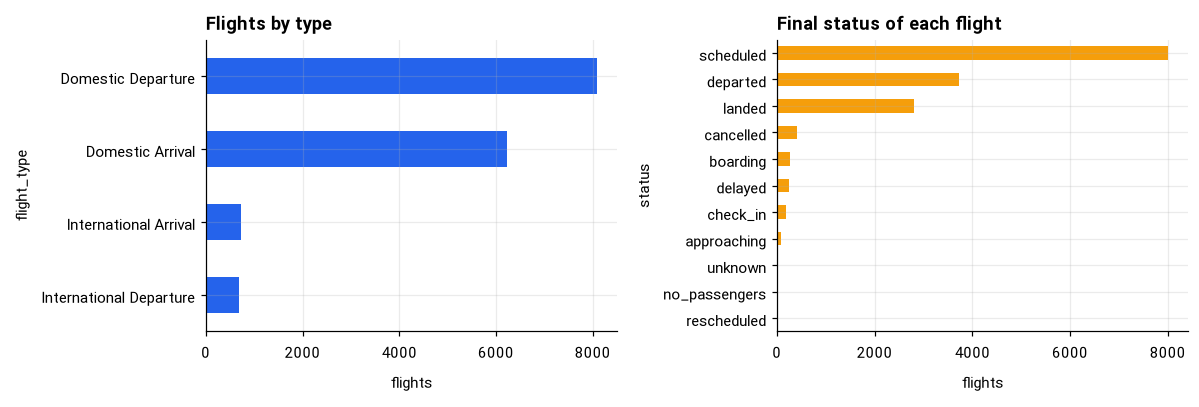

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
flights["flight_type"].value_counts().sort_values().plot.barh(ax=left, color=BLUE)
left.set_title("Flights by type")
left.set_xlabel("flights")
flights["status"].value_counts().sort_values().plot.barh(ax=right, color=ORANGE)
right.set_title("Final status of each flight")
right.set_xlabel("flights")
plt.tight_layout()

Status text on the boards varies in spelling and embeds times (`پروازکرد04:57`, `پرواز كرد`). The first version kept only one spelling and lost a third of the departures; the cleaner now maps every variant to one of these states.

## Where the departures come from

فرودگاه مهرآباد has 59% of all training departures


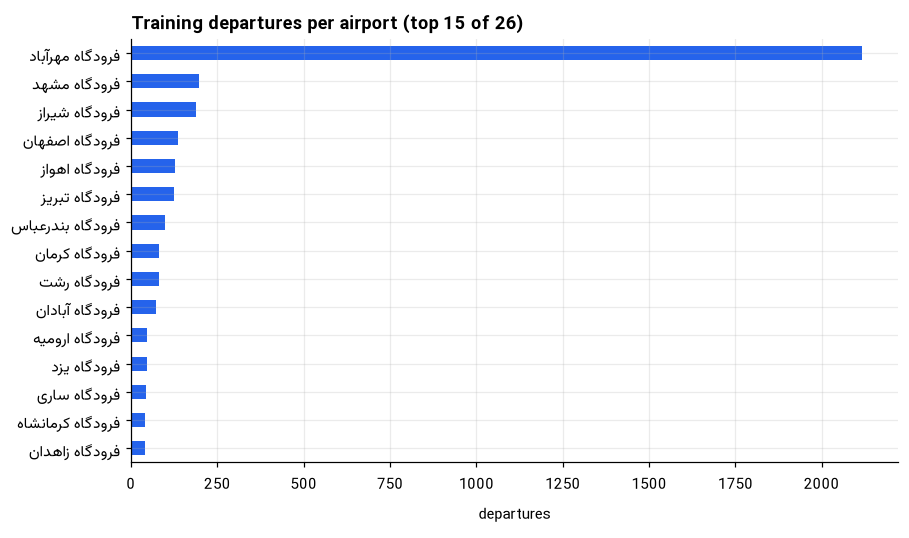

In [5]:
by_airport = departures["airport"].value_counts()
top = by_airport.head(15).sort_values()
ax = top.plot.barh(color=BLUE, figsize=(9, 5))
ax.set_ylabel("")
ax.set_title(f"Training departures per airport (top 15 of {by_airport.size})")
ax.set_xlabel("departures")
share = by_airport.iloc[0] / by_airport.sum()
print(f"{by_airport.index[0]} has {share:.0%} of all training departures")

## Registrations: the gap that matters

Overall: 59% of departures have a registration


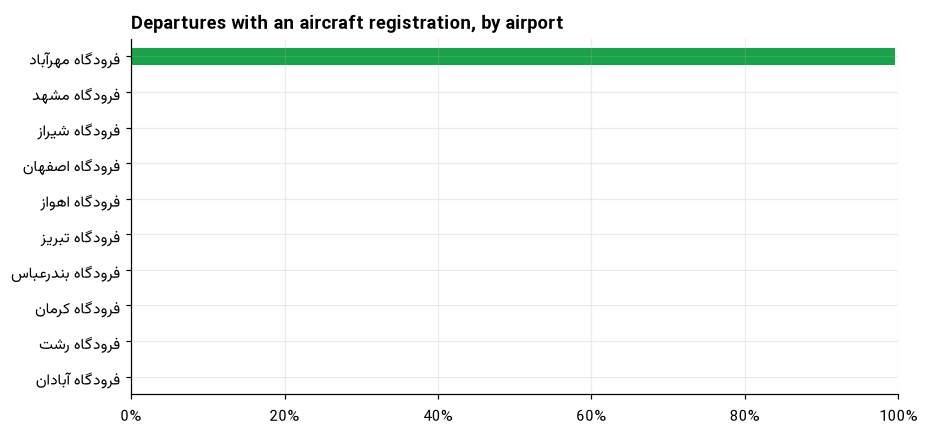

In [6]:
registered = departures.assign(has_registration=departures["register"].notna())
coverage = registered.groupby("airport")["has_registration"].agg(["mean", "size"]).sort_values("size", ascending=False).head(10)
ax = coverage["mean"].iloc[::-1].plot.barh(color=GREEN, figsize=(9, 4.2))
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Departures with an aircraft registration, by airport")
print(f"Overall: {registered['has_registration'].mean():.0%} of departures have a registration")

A registration links a flight to its aircraft, and through it to the aircraft's earlier flights that day: its inbound arrival and its previous delay. Those are the most useful features (notebook 2), and the boards publish registrations almost only at Mehrabad.

## How much was scraped each day

Text(0.5, 0, '')

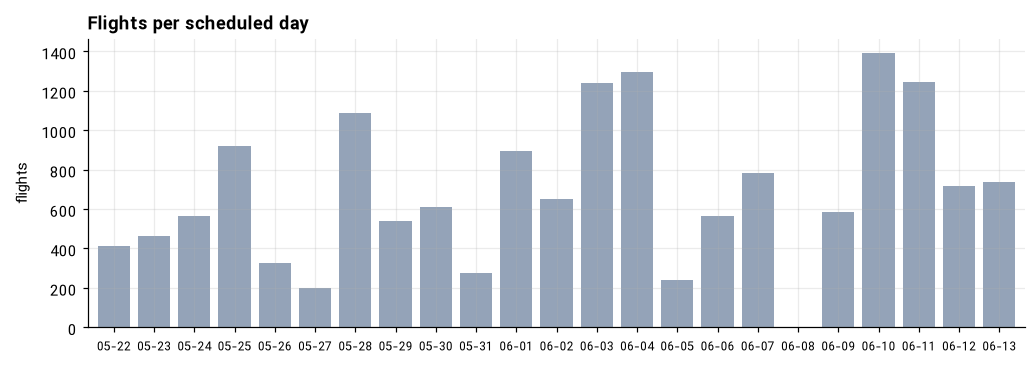

In [7]:
per_day = flights.set_index("scheduled_datetime").resample("D").size()
ax = per_day.plot.bar(color=GREY, figsize=(11, 3.4), width=0.8)
ax.set_xticklabels([d.strftime("%m-%d") for d in per_day.index], rotation=0, fontsize=8)
ax.set_title("Flights per scheduled day")
ax.set_ylabel("flights")
ax.set_xlabel("")

## Takeaways

- Of 15,732 flights in the archive, 3,574 are domestic departures that departed with a known delay; most of the rest are arrivals (used as context for features) and flights that never reached "departed".
- The data is three weeks long, and Mehrabad has 59% of the departures.
- Registrations, and therefore aircraft-rotation features, exist almost only at Mehrabad. That shapes the features (notebook 2) and the model's limits (notebook 4).